# US Grocery and Gas Prices (2015–2026)
**Author:** Baizhan Zere (individual project)  
**Tools:** Python, Pandas, NumPy, Matplotlib/Seaborn, Jupyter Notebook

**Research questions**
1. Which everyday items became the most expensive between 2015 and 2026,and how does this compare with general inflation (CPI)?
2. Do gas prices move together with food prices?
3. How did prices behave during the COVID-19 recession and the 2021–2023 inflation wave?

**Data sources**
| # | Source | Type | Use |
|---|--------|------|-----|
| 1 | Kaggle: *US Grocery and Gas Prices (2015-2026)*, file `us_average_prices_monthly.csv` | CSV dataset (main data) | monthly average prices of 74 items |
| 2 | **BLS Public Data API v1** (`api.bls.gov`) | **API** | official CPI-U (all items) as an inflation benchmark |
| 3 | NBER *https://www.nber.org/research/business-cycle-dating* | **Web scraping** (requests + BeautifulSoup) | recession periods, merged by month |

In [ ]:
import re, time, os
from urllib import robotparser
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from bs4 import BeautifulSoup


HEADERS = {"User-Agent": "SIS1-DataCollection-StudentProject/1.0 (educational use)"}
CSV_PATH = "us_average_prices_monthly.csv"
START, END = "2015-01-01", "2026-07-01"

## 1. Source 1: Kaggle CSV (raw data)

In [24]:
raw = pd.read_csv(CSV_PATH)
print(raw.shape)
raw.info()
raw.head(10)

(8869, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8869 entries, 0 to 8868
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       8869 non-null   object 
 1   year       8869 non-null   int64  
 2   month      8869 non-null   int64  
 3   item       8869 non-null   object 
 4   unit       8869 non-null   object 
 5   category   8869 non-null   object 
 6   price      8869 non-null   float64
 7   series_id  8869 non-null   object 
dtypes: float64(1), int64(2), object(5)
memory usage: 554.4+ KB


,date,year,month,item,unit,category,price,series_id
0,2015-01-01,2015,1,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.211,APU0000FD2101
1,2015-02-01,2015,2,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.221,APU0000FD2101
2,2015-03-01,2015,3,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.176,APU0000FD2101
3,2015-04-01,2015,4,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",2.971,APU0000FD2101
4,2015-05-01,2015,5,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.045,APU0000FD2101
5,2015-06-01,2015,6,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.020,APU0000FD2101
6,2015-07-01,2015,7,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.031,APU0000FD2101
7,2015-08-01,2015,8,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.103,APU0000FD2101
8,2015-09-01,2015,9,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.124,APU0000FD2101
9,2015-10-01,2015,10,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.155,APU0000FD2101


In [25]:
DATE_COL = ITEM_COL = PRICE_COL = None   

def find_col(cols, keys):
    for k in keys:
        for c in cols:
            if k in c.lower(): return c
    return None

cols = list(raw.columns)
DATE_COL  = DATE_COL  or find_col(cols, ["date", "month", "period", "time", "year"])
ITEM_COL  = ITEM_COL  or find_col(cols, ["item", "product", "commodity", "name", "series", "description", "category"])
PRICE_COL = PRICE_COL or find_col(cols, ["price", "value", "avg", "average", "amount"])
print("date:", DATE_COL, "| item:", ITEM_COL, "| price:", PRICE_COL)

if ITEM_COL is None or PRICE_COL is None or ITEM_COL == DATE_COL:
    # wide format -> melt to long!
    value_cols = [c for c in cols if c != DATE_COL and pd.api.types.is_numeric_dtype(raw[c])]
    long_df = raw.melt(id_vars=DATE_COL, value_vars=value_cols, var_name="item", value_name="price")
    print("Wide format detected, melted", len(value_cols), "item columns")
else:
    long_df = raw[[DATE_COL, ITEM_COL, PRICE_COL]].rename(columns={ITEM_COL: "item", PRICE_COL: "price"})
long_df = long_df.rename(columns={DATE_COL: "date"})
long_df.head()

date: date | item: item | price: price


,date,item,price
0,2015-01-01,All Ham (Excluding Canned Ham and Luncheon Sli...,3.211
1,2015-02-01,All Ham (Excluding Canned Ham and Luncheon Sli...,3.221
2,2015-03-01,All Ham (Excluding Canned Ham and Luncheon Sli...,3.176
3,2015-04-01,All Ham (Excluding Canned Ham and Luncheon Sli...,2.971
4,2015-05-01,All Ham (Excluding Canned Ham and Luncheon Sli...,3.045


## 2. Source 2: BLS API (CPI-U, all items)

In [26]:
BLS_URL = "https://api.bls.gov/publicAPI/v1/timeseries/data/"
CPI_SERIES = "CUUR0000SA0"          # CPI-U(Consumer Price Index for Urban consumers), U.S. city average, all items, not seasonally adjusted

def bls_fetch(series_id, start_year, end_year):
    r = requests.post(BLS_URL, json={"seriesid": [series_id],
                                     "startyear": str(start_year), "endyear": str(end_year)},
                      headers=HEADERS, timeout=30)
    r.raise_for_status()
    js = r.json()
    if js.get("status") != "REQUEST_SUCCEEDED":
        raise RuntimeError(js.get("message"))
    return js["Results"]["series"][0]["data"]

records = bls_fetch(CPI_SERIES, 2015, 2024) + bls_fetch(CPI_SERIES, 2025, 2026)
cpi_raw = pd.DataFrame(records)
cpi_raw.to_csv("cpi_raw.csv", index=False)
print(cpi_raw.shape); cpi_raw.head()

(141, 6)


,year,period,periodName,value,footnotes,latest
0,2024,M12,December,315.605,[{}],NaN
1,2024,M11,November,315.493,[{}],NaN
2,2024,M10,October,315.664,[{}],NaN
3,2024,M09,September,315.301,[{}],NaN
4,2024,M08,August,314.796,[{}],NaN


## 3. Source 3 — Web scraping: US recessions (NBER)

In [27]:
rp = robotparser.RobotFileParser("https://www.nber.org/robots.txt"); rp.read()
URL = "https://www.nber.org/research/business-cycle-dating"
print("Allowed by robots.txt:", rp.can_fetch(HEADERS["User-Agent"], URL))
if not rp.can_fetch(HEADERS["User-Agent"], URL):
    raise PermissionError("Scraping is not allowed by robots.txt")

response = requests.get(URL, headers=HEADERS, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

paragraph = soup.find(
    "p",
    string=lambda s: s is not None
    and "most recent peak occurred" in s
)

if paragraph is None:
    raise ValueError("NBER recession paragraph not found")

paragraph_text = paragraph.get_text(" ", strip=True)
print(paragraph_text)
peak_match = re.search(
    r"peak occurred in ([A-Za-z]+ \d{4})",
    paragraph_text
)

trough_match = re.search(
    r"trough occurred in ([A-Za-z]+ \d{4})",
    paragraph_text
)

print("Peak:", peak_match.group(1))
print("Trough:", trough_match.group(1))

Allowed by robots.txt: True
The NBER’s Business Cycle Dating Committee maintains a chronology of US business cycles. The chronology identifies the months of peaks and troughs of economic activity. Expansions are the periods between a trough and a peak; recessions are the periods between a peak and a trough. By convention, the NBER classifies the peak month as the last month of the expansion and the trough month as the last month of the recession. Expansion is the normal state of the economy; most recessions are brief. However, the time that it takes for the economy to return to its previous peak level of activity or its previous trend path may be quite extended. According to the NBER chronology, the most recent peak occurred in February 2020. The most recent trough occurred in April 2020.
Peak: February 2020
Trough: April 2020


## 4. Data cleaning

### 4.1 Kaggle prices

In [28]:
print("Missing values:\n", long_df.isna().sum())
print("Duplicated rows:", long_df.duplicated().sum())
print("Dtypes:\n", long_df.dtypes)

Missing values:
 date     0
item     0
price    0
dtype: int64
Duplicated rows: 0
Dtypes:
 date      object
item      object
price    float64
dtype: object


In [29]:
prices = long_df.copy()
prices["item"]  = prices["item"].astype(str).str.strip()
prices["date"]  = pd.to_datetime(prices["date"], errors="coerce")
prices["price"] = pd.to_numeric(prices["price"].astype(str).str.replace(r"[\$,]", "", regex=True), errors="coerce")

n0 = len(prices)
prices = prices.dropna(subset=["date"])                          # unparseable dates
prices["date"] = prices["date"].dt.to_period("M").dt.to_timestamp()   # normalise to 1st day of month
prices = prices.drop_duplicates()
# if an item has several values in a month -> average them
prices = prices.groupby(["item", "date"], as_index=False)["price"].mean()
# non-positive prices are invalid
bad = (prices["price"] <= 0).sum()
prices.loc[prices["price"] <= 0, "price"] = np.nan
# missing months: fill short gaps (<=2 months) per item by interpolation
prices = prices.sort_values(["item", "date"])
prices["price"] = prices.groupby("item")["price"].transform(lambda s: s.interpolate(limit=2))
missing = prices["price"].isna().sum()
prices = prices.dropna(subset=["price"])
prices = prices[(prices.date >= START) & (prices.date <= END)]
print(f"rows {n0} -> {len(prices)} | invalid prices: {bad} | unrecoverable missing dropped: {missing}")
print("Items:", prices.item.nunique(), "| period:", prices.date.min().date(), "→", prices.date.max().date())

rows 8869 -> 8869 | invalid prices: 0 | unrecoverable missing dropped: 0
Items: 74 | period: 2015-01-01 → 2026-07-01


### 4.2 CPI (API)

In [30]:
cpi = (cpi_raw[cpi_raw["period"].str.startswith("M") & (cpi_raw["period"] != "M13")]   # M13 = annual average
       .assign(date=lambda d: pd.to_datetime(d["year"] + "-" + d["period"].str[1:] + "-01"),
               cpi=lambda d: pd.to_numeric(d["value"], errors="coerce"))
       [["date", "cpi"]]
       .drop_duplicates("date").dropna().sort_values("date").reset_index(drop=True))
print(cpi.shape, cpi.date.min().date(), "→", cpi.date.max().date())
cpi.tail()

(140, 2) 2015-01-01 → 2026-09-01


,date,cpi
135,2026-05-01,335.123
136,2026-06-01,333.952
137,2026-07-01,333.918
138,2026-08-01,334.980
139,2026-09-01,336.940


### 4.3 Recessions (scraped)

In [31]:
peak_date = pd.to_datetime(
    peak_match.group(1),
    format="%B %Y"
)

trough_date = pd.to_datetime(
    trough_match.group(1),
    format="%B %Y"
)

recessions = pd.DataFrame([
    {
        "name": "COVID-19 recession",
        "start": peak_date + pd.DateOffset(months=1),
        "end": trough_date
    }
])

recent = recessions[recessions["end"] >= START]

print("Recessions overlapping the study period:")
display(recent)

Recessions overlapping the study period:


,name,start,end
0,COVID-19 recession,2020-03-01,2020-04-01


## 5. Transformation, feature engineering and merging

In [32]:
# --- helper: find items by keyword ---
def pick(*keys):
    for k in keys:
        m = [i for i in prices.item.unique() if k.lower() in i.lower()]
        if m: return sorted(m, key=len)[0]
    return None

# wide table: one column per item
wide = prices.pivot(index="date", columns="item", values="price")

# percent change since the first month, and year-over-year
first = wide.apply(lambda s: s.dropna().iloc[0])
last  = wide.apply(lambda s: s.dropna().iloc[-1])
change = ((last / first - 1) * 100).rename("pct_change_total").sort_values(ascending=False)
yoy = wide.pct_change(12, fill_method=None) * 100

# merge with CPI (by month) and recession flag (by month)
monthly = wide.reset_index().merge(cpi, on="date", how="left", validate="one_to_one")
monthly["recession"] = monthly["date"].apply(lambda d: any((d >= s) and (d <= e) for s, e in zip(recessions.start, recessions.end)))
monthly["cpi_index"] = monthly["cpi"] / monthly["cpi"].dropna().iloc[0] * 100      # CPI rebased to 100 at start

# long merged dataset for item-level analysis
merged = (prices.merge(cpi, on="date", how="left")
                .assign(recession=lambda d: d.date.isin(monthly.loc[monthly.recession, "date"])))
merged["price_index"] = merged.groupby("item")["price"].transform(lambda s: s / s.iloc[0] * 100)
merged.to_csv("merged_dataset.csv", index=False)
print("CPI coverage:", f"{monthly.cpi.notna().mean():.0%}", "| recession months:", int(monthly.recession.sum()))
merged.head()

CPI coverage: 99% | recession months: 2


,item,date,price,cpi,recession,price_index
0,All Ham (Excluding Canned Ham and Luncheon Sli...,2015-01-01,3.211,233.707,False,100.000000
1,All Ham (Excluding Canned Ham and Luncheon Sli...,2015-02-01,3.221,234.722,False,100.311429
2,All Ham (Excluding Canned Ham and Luncheon Sli...,2015-03-01,3.176,236.119,False,98.909997
3,All Ham (Excluding Canned Ham and Luncheon Sli...,2015-04-01,2.971,236.599,False,92.525693
4,All Ham (Excluding Canned Ham and Luncheon Sli...,2015-05-01,3.045,237.805,False,94.830271


## 6. Exploratory data analysis

In [33]:
# Align CPI with the months actually covered by the grocery/gas dataset.
common_start = max(prices["date"].min(), cpi["date"].min())
common_end = min(prices["date"].max(), cpi["date"].max())
cpi_aligned = cpi.loc[cpi["date"].between(common_start, common_end)].sort_values("date")
if cpi_aligned.empty or len(cpi_aligned) < 2:
    raise ValueError("Not enough overlapping CPI observations for comparison")
total_cpi = (cpi_aligned["cpi"].iloc[-1] / cpi_aligned["cpi"].iloc[0] - 1) * 100
print(f"CPI comparison period: {common_start:%Y-%m} to {common_end:%Y-%m}")
print(f"General inflation (CPI) over the aligned period: {total_cpi:.1f}%\n")
print("Top 10 biggest price increases (%):"); print(change.head(10).round(1))
print("\nBottom 5 (smallest increase / decrease):"); print(change.tail(5).round(1))
print(f"\nItems that rose faster than CPI: {(change > total_cpi).sum()} of {len(change)}")
print("Note: individual item first/last dates may differ from the CPI comparison window.")


CPI comparison period: 2015-01 to 2026-07
General inflation (CPI) over the aligned period: 42.9%

Top 10 biggest price increases (%):
item
Gasoline, unleaded premium                      101.3
Coffee, 100%, ground roast, all sizes            96.6
Gasoline, unleaded midgrade                      95.9
Gasoline, all types                              95.5
Gasoline, unleaded regular                       94.0
Steak, sirloin, USDA Choice, boneless            80.6
All soft drinks, 12 pk, 12 oz., cans             80.4
Orange juice, frozen concentrate, 12 oz. can     76.3
All Uncooked Beef Steaks                         73.5
Automotive diesel fuel                           71.3
Name: pct_change_total, dtype: float64

Bottom 5 (smallest increase / decrease):
item
Bologna, all beef or mixed                                           -5.6
Pears, Anjou                                                         -5.9
Margarine, soft, tubs                                               -12.1
Chuck roast, 

In [34]:
prices.groupby("item")["price"].describe().round(2).sort_values("mean", ascending=False).head(15)

,count,mean,std,min,25%,50%,75%,max
item,,,,,,,,
"Wine, red and white table, all sizes, any origin",138.0,12.95,0.69,11.88,12.36,12.90,13.52,14.25
"Steak, sirloin, USDA Choice, boneless",138.0,9.96,1.88,7.79,8.35,9.03,11.50,14.73
All Uncooked Beef Steaks,138.0,9.06,1.67,7.09,7.65,8.23,10.52,13.06
"Steak, round, USDA Choice, boneless",138.0,6.93,1.22,5.51,5.86,6.45,7.66,10.10
"Steak, round, graded and ungraded, excluding USDA Prime and Choice",67.0,6.60,1.19,5.30,5.86,6.02,7.72,9.34
"Beef for stew, boneless",127.0,6.48,1.06,5.04,5.59,6.31,7.16,9.30
All Uncooked Beef Roasts,138.0,6.48,1.17,5.11,5.48,6.05,7.24,9.57
"Chuck roast, USDA Choice, boneless",138.0,6.42,1.26,4.79,5.32,5.97,7.30,9.63
"Ground beef, lean and extra lean",138.0,6.27,0.86,5.19,5.62,6.10,6.69,8.65


In [35]:
# Items of interest (auto-matched by keyword); inspect actual matched product names.
focus = {"Gasoline": pick("gasoline", "gas"), "Eggs": pick("egg"), "Milk": pick("milk"),
         "Beef": pick("beef"), "Coffee": pick("coffee"), "Bread": pick("bread")}
focus = {k: v for k, v in focus.items() if v}
print("Selected product series:")
for category, product in focus.items():
    print(f"  {category}: {product}")

# Correlation of month-over-month changes; avoid implicit filling of missing prices.
mom = wide[list(focus.values())].pct_change(fill_method=None).dropna()
mom.columns = list(focus.keys())
corr = mom.corr(method="spearman")
corr.round(2)


Selected product series:
  Gasoline: Gasoline, all types
  Eggs: Eggs, grade A, large
  Milk: Milk, fresh, whole, fortified
  Beef: Ground beef, 100% beef
  Coffee: Coffee, 100%, ground roast, all sizes
  Bread: Bread, white, pan


,Gasoline,Eggs,Milk,Beef,Coffee,Bread
Gasoline,1.00,-0.18,-0.07,-0.05,0.00,-0.09
Eggs,-0.18,1.00,0.15,0.05,0.14,0.14
Milk,-0.07,0.15,1.00,0.11,0.12,-0.02
Beef,-0.05,0.05,0.11,1.00,0.20,0.02
Coffee,0.00,0.14,0.12,0.20,1.00,-0.03
Bread,-0.09,0.14,-0.02,0.02,-0.03,1.00


In [36]:
# Recession vs. normal months: average monthly change of the focus items
tmp = mom.join(monthly.set_index("date")["recession"])
tmp.groupby("recession").mean().mul(100).round(3)

,Gasoline,Eggs,Milk,Beef,Coffee,Bread
recession,,,,,,
False,1.052,0.727,0.085,0.337,0.587,0.188
True,-12.185,18.819,1.106,2.410,1.704,1.128


## 7. Visualizations

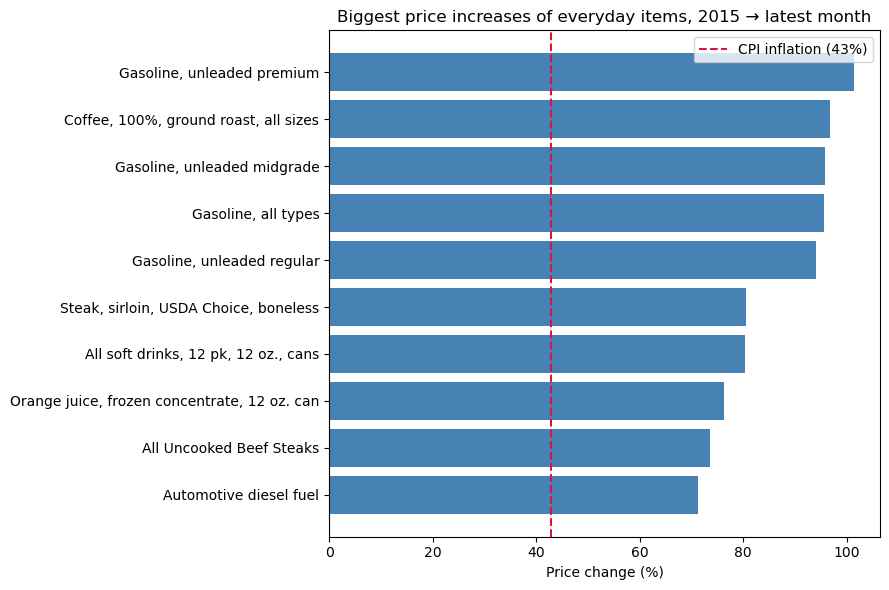

In [37]:
top = change.head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color="steelblue")
ax.axvline(total_cpi, color="crimson", ls="--", label=f"CPI inflation ({total_cpi:.0f}%)")
ax.set_title("Biggest price increases of everyday items, 2015 → latest month")
ax.set_xlabel("Price change (%)"); ax.legend()
plt.tight_layout(); plt.savefig("plot1_top_increases.png", dpi=150); plt.show()

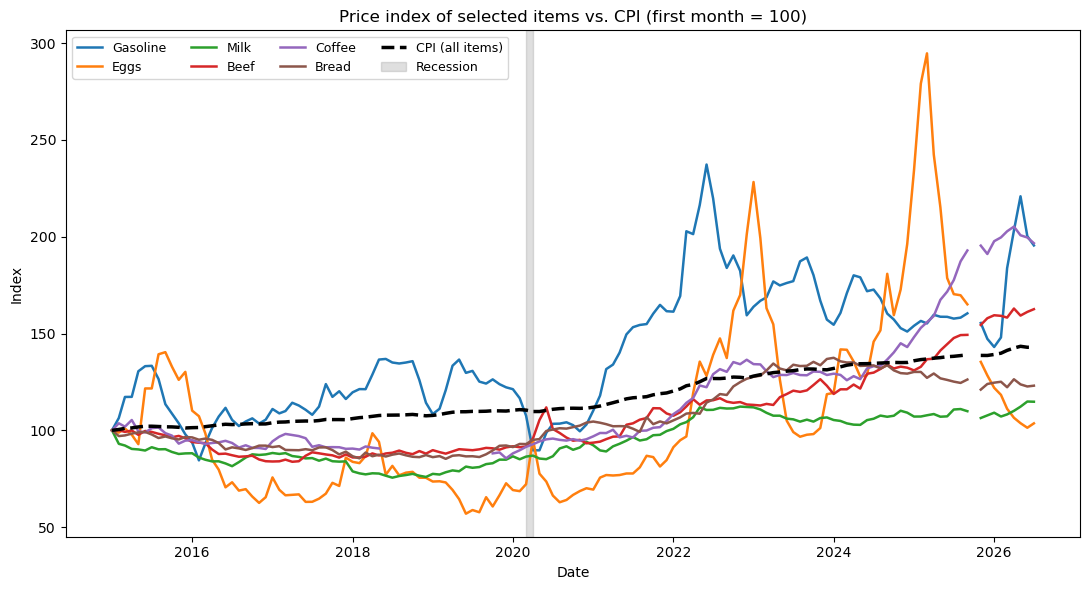

In [38]:
fig, ax = plt.subplots(figsize=(11, 6))
for label, item in focus.items():
    s = wide[item]; ax.plot(s.index, s / s.dropna().iloc[0] * 100, label=label, lw=1.8)
ax.plot(monthly.date, monthly.cpi_index, color="black", lw=2.5, ls="--", label="CPI (all items)")
for _, r in recent.iterrows():
    ax.axvspan(r.start, r.end, color="grey", alpha=.25, label="Recession" if _ == recent.index[0] else None)
ax.set_title("Price index of selected items vs. CPI (first month = 100)")
ax.set_ylabel("Index"); ax.set_xlabel("Date"); ax.legend(ncol=4, fontsize=9)
plt.tight_layout(); plt.savefig("plot2_index_vs_cpi.png", dpi=150); plt.show()

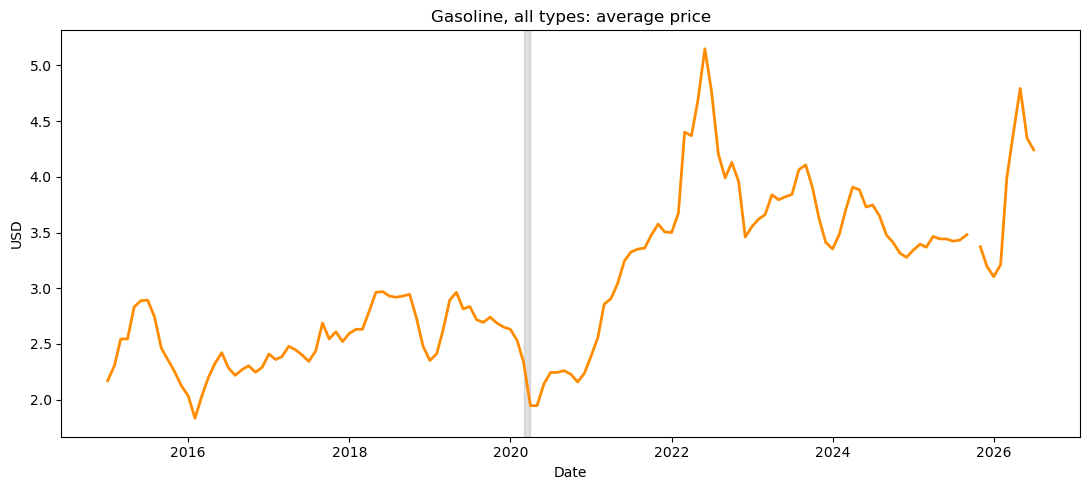

In [39]:
g = focus.get("Gasoline")
if g:
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(wide.index, wide[g], color="darkorange", lw=2)
    for _, r in recent.iterrows(): ax.axvspan(r.start, r.end, color="grey", alpha=.25)
    ax.set_title(f"{g}: average price"); ax.set_ylabel("USD"); ax.set_xlabel("Date")
    plt.tight_layout(); plt.savefig("plot3_gasoline.png", dpi=150); plt.show()

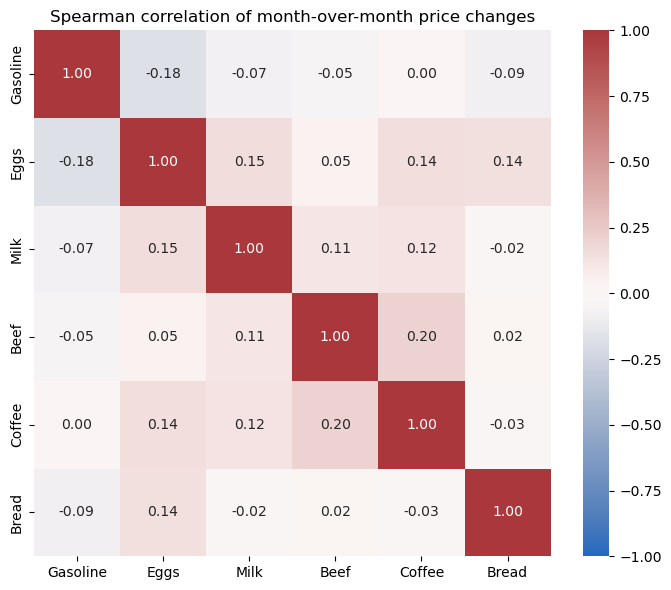

In [40]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation of month-over-month price changes")
plt.tight_layout();
plt.show()

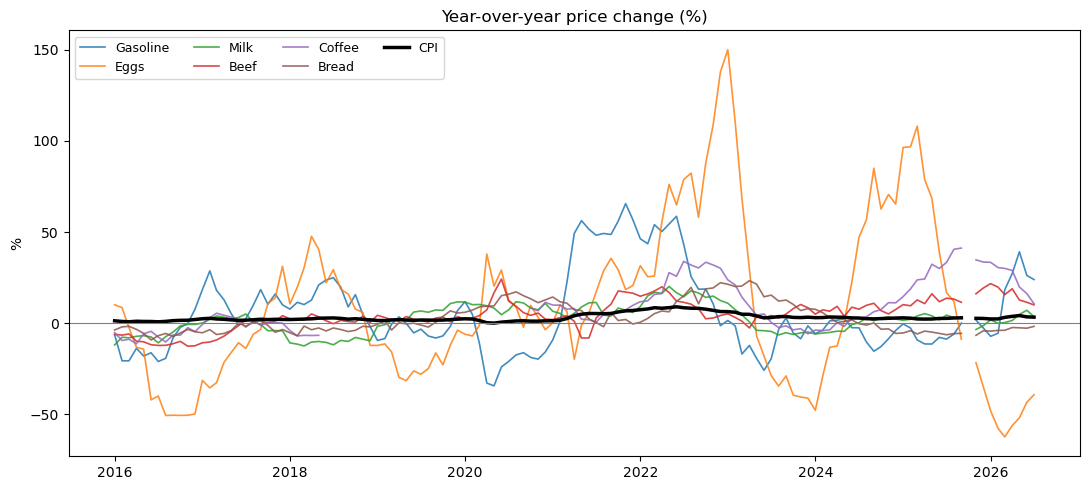

In [41]:
# Plot 5 — Year-over-year inflation: focus items vs CPI
fig, ax = plt.subplots(figsize=(11, 5))
for label, item in focus.items(): ax.plot(yoy.index, yoy[item], lw=1.2, label=label, alpha=.85)
ax.plot(monthly.date, monthly.cpi.pct_change(12, fill_method=None) * 100, color="black", lw=2.5, label="CPI")
ax.axhline(0, color="grey", lw=.8)
ax.set_title("Year-over-year price change (%)"); ax.set_ylabel("%"); ax.legend(ncol=4, fontsize=9)
plt.tight_layout();
plt.show()

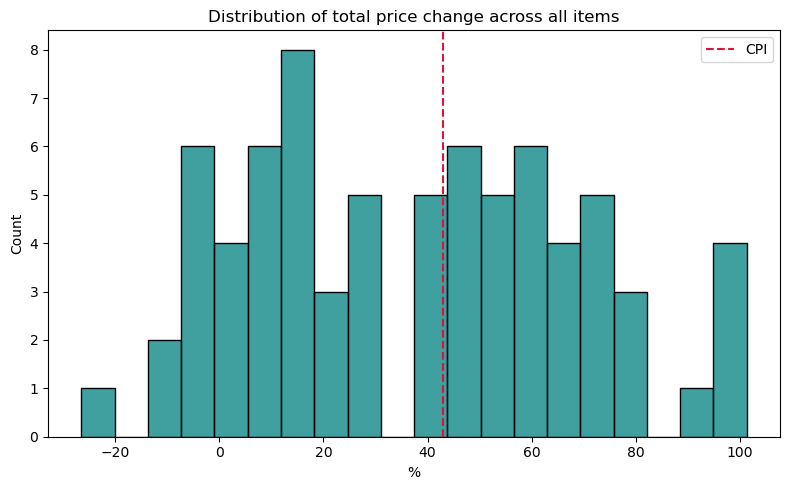

In [42]:
# Plot 6 — Distribution of total price change across all items
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(change, bins=20, color="teal", ax=ax); ax.axvline(total_cpi, color="crimson", ls="--", label="CPI")
ax.set_title("Distribution of total price change across all items"); ax.set_xlabel("%"); ax.legend()
plt.tight_layout(); plt.savefig("plot6_distribution.png", dpi=150); plt.show()

## 8. Key findings

In [43]:
print(f"Items analysed: {wide.shape[1]}; months: {wide.shape[0]}")
print(f"CPI inflation: {total_cpi:.1f}%")
print(f"Largest increase: {change.index[0]} (+{change.iloc[0]:.1f}%); smallest: {change.index[-1]} ({change.iloc[-1]:+.1f}%)")
print(f"Items outpacing CPI: {(change > total_cpi).sum()} / {len(change)}")
if "Gasoline" in corr.index:
    print("Spearman corr. of gasoline monthly change with:", corr["Gasoline"].drop("Gasoline").round(2).to_dict())

Items analysed: 74; months: 139
CPI inflation: 42.9%
Largest increase: Gasoline, unleaded premium (+101.3%); smallest: Grapes, Thompson Seedless (-26.5%)
Items outpacing CPI: 35 / 74
Spearman corr. of gasoline monthly change with: {'Eggs': -0.18, 'Milk': -0.07, 'Beef': -0.05, 'Coffee': 0.0, 'Bread': -0.09}


### Conclusions
- The item with the largest first-to-last price increase is reported in the summary output above; compare it against the **aligned-period** CPI benchmark shown there.
- The gasoline–eggs Spearman correlation is weakly negative (approximately −0.18 in the saved analysis), not moderate.
- The analysis describes price movements during the COVID-19 recession and the subsequent period, without claiming causation.
- NBER identifies February 2020 as the peak and April 2020 as the trough; March–April 2020 are classified as recession months here.
- The largest price increase was for premium gasoline, which increased by 101.3%. Ground coffee increased by 96.6%, and sirloin steak by 80.6%. General inflation, measured by CPI, was 42.9%. Overall, 35 out of 74 items increased faster than general inflation.
- During the COVID-19 recession in March and April 2020, gasoline prices decreased sharply, with an average monthly change of −12.19%. In contrast, egg prices increased by an average of 18.82% per month. Other selected food prices also increased.
- During the 2021–2023 inflation wave, many grocery and gasoline prices increased significantly, although their patterns were different. This shows that economic shocks can affect product categories differently.
### Limitations
- National averages hide regional differences, and the dataset covers selected items only.
- Some item series begin/end in different months, so their first-to-last changes are not perfectly matched to the CPI comparison window.
- Only one recession overlaps the study period; recession comparisons are descriptive.
- Correlation does not imply causation.
